In [1]:
import pandas as pd
df = pd.read_csv('amz_data.csv')

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [15]:
df['category'].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [19]:
my_table = pd.crosstab(index = df['category'],  columns='count').sort_values(by='count', ascending=False)
my_table

col_0,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978
...,...
Motorbike Chassis,107
Plugs,107
Alexa Built-In Devices,107


<Axes: xlabel='category', ylabel='count'>

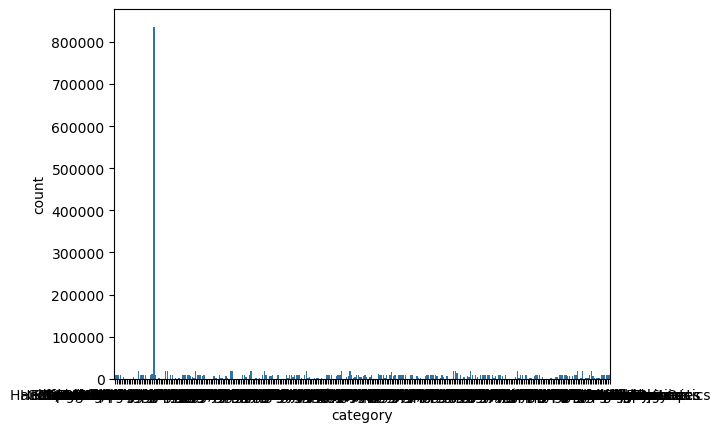

In [9]:
import seaborn as sns
import matplotlib as plt
sns.countplot(data=df, x='category')

<Axes: ylabel='count'>

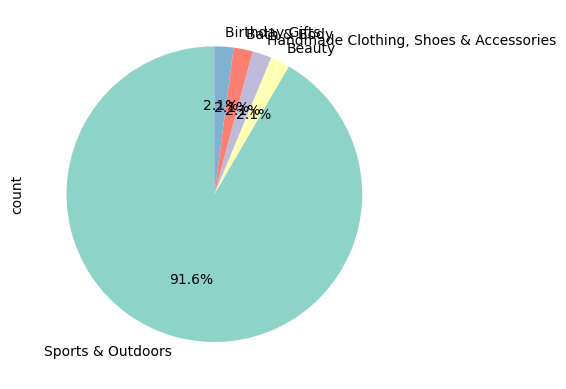

In [25]:
most_rel_cats = ['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories', 'Bath & Body', 'Birthday Gifts']
filtered_df = df[df['category'].isin(most_rel_cats)]
#sns.countplot(data=filtered_df, x='category')
filtered_df['category'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

In [47]:
#Part 2: Delving into Product Pricing
#Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

#Measures of Centrality:
#Calculate the mean, median, and mode for the price of products.
#df['price'].mean() #89.24
#df['price'].mode() #9.99
#df['price'].median() #19.09

#What's the average price point of products listed? -> 89.24
#How does this compare with the most common price point (mode)? -> its far beyond, so there are some massive outliers at the higher side of spectrum

#Measures of Dispersion:
#Determine the variance, standard deviation, range, and interquartile range for product price.
#How varied are the product prices? Are there any indicators of a significant spread in prices?
df['price'].describe().round(2)
#std = 345.61
#range is 100000 - 0
#iqr is 45,99 - 9,99 = 36
df['price'] .var() #-> 119445.49
#range compare to iqr is a massive difference! (also mode to mean) -> heavy outliers...

119445.48532256528

<Axes: xlabel='price', ylabel='Count'>

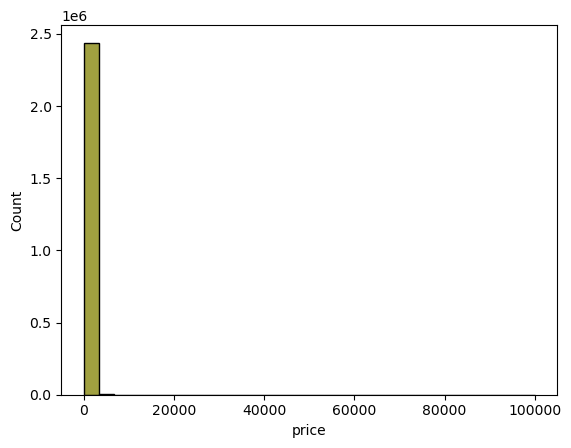

In [76]:
#Visualizations:
#Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices.
#If its hard to read these diagrams, think why this is, and explain how it could be solved..
#Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential
#outliers in product pricing.

sns.histplot(df['price'], bins = 30, color="olive")

In [114]:
#part 3 rating
#Measures of Centrality:
#Calculate the mean, median, and mode for the rating of products.
#How do customers generally rate products? Is there a common trend?
#df['stars'].mean() #2.15
#df['stars'].mode() #0.0
#df['stars'].median() #0.0
df['stars'].value_counts()

#there is a common trend to not rate (->0.0), which dominates mean mode median. Furthermore, there is a trend to rate positive
#-> after the 0.0 all the most common ratings are above 3.5

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

In [126]:
#Measures of Dispersion:
#Determine the variance, standard deviation, and interquartile range for product rating.
#Are the ratings consistent, or is there a wide variation in customer feedback?
df['stars'].describe().round(2)
#std 2.19
#var 4.8
#iqr: 4.4
#medium variation?

count    2443651.00
mean           2.15
std            2.19
min            0.00
25%            0.00
50%            0.00
75%            4.40
max            5.00
Name: stars, dtype: float64

In [130]:
#Shape of the Distribution:
#Calculate the skewness and kurtosis for the rating column.
#Are the ratings normally distributed, or do they lean towards higher or lower values?
skew = df['stars'].skew()
kurtosis = df['stars'].kurtosis()

skew, kurtosis

#almost symmetrically, very small positive skewness: tends to lean to the left a bit (lean to lower values)
#negative kurtosis -> excess kurtosis, so standard distribition's 3 +/- the excess kurtosis so actual kurtosis here is 1.1
# -> flatter curve, fewer extreme values than normal distribution, tails are thinner, peak is flatter

(0.08120735761080985, -1.9260061280432985)

<Axes: xlabel='stars', ylabel='Count'>

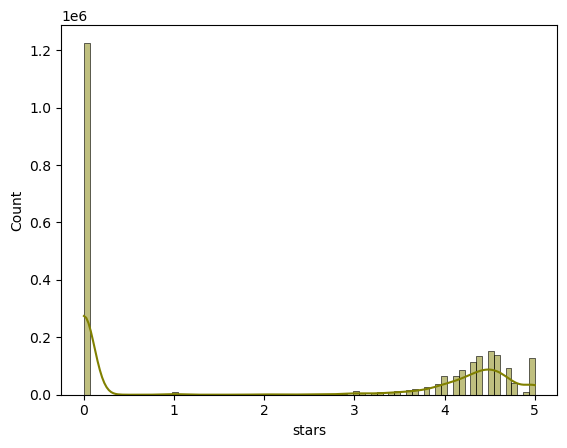

In [138]:
#Visualizations:
#Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
#yes the zero as already identified

sns.histplot(df['stars'], kde=True, color="olive")